In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from umap import UMAP

In [2]:
# Transcriptomic label columns 
CLASS_COL =    'class_label_Hierarchical'
SUBCLASS_COL = 'subclass_label_Hierarchical'
CLUSTER_COL =  'cluster_label_Hierarchical'

# UMAP parameters
PCA_VARIANCE = 0.95
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
RANDOM_STATE = 0

# Save root 
OUT_DIR = Path('/root/capsule/data/human/umaps') / '20260807'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

#Metadata 
metadata_path =        DATA_ROOT / 'human' / 'metadata' / '20260807' / 'human_metadata.csv'
morpho_feature_file =  DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide_imputed.csv'
ephys_feature_file =   DATA_ROOT / 'human' / 'electrophysiology' / 'features' / '20260807' / 'ephys_features_imputed.csv'

In [3]:
def prepare_morphology_features(morpho_df, metadata):
    """
    Prepare morphology features for UMAP.
    - Merges with metadata on specimen_id
    - Fills apical dendrite NaN with 0 (cells without apicals)
    - Drops remaining NaN rows
    """
    # Merge with metadata to get specimen_id
    morpho_df = morpho_df.rename(columns={'cell_id': 'specimen_id'}, errors='ignore')
    
    # Get feature columns (exclude metadata)
    feature_cols = [c for c in morpho_df.columns if c not in 
                    [CLASS_COL, SUBCLASS_COL, CLUSTER_COL, 'specimen_id']]
    
    # Identify apical dendrite features
    apical_cols = [c for c in feature_cols if 'apical' in c.lower()]
    
    # Fill apical NaN with 0 (cells without apical dendrites)
    morpho_df[apical_cols] = morpho_df[apical_cols].fillna(0)
    print(f"  Filled {len(apical_cols)} apical dendrite features with 0")
    
    # Drop rows with any remaining NaN
    before_count = len(morpho_df)
    morpho_df = morpho_df.dropna(subset=feature_cols)
    after_count = len(morpho_df)
    
    if before_count != after_count:
        print(f"  Dropped {before_count - after_count} rows with remaining NaN")
    
    # Keep only specimen_id and feature columns
    result_df = morpho_df[['specimen_id'] + feature_cols].copy()
    
    print(f"  Final: {len(result_df)} cells × {len(feature_cols)} features")
    
    return result_df

In [4]:
def prepare_ephys_features(ephys_df, metadata):
    """
    Prepare electrophysiology features for UMAP.
    - Data is pre-imputed
    - Validates no NaN values remain
    """
    # Ensure specimen_id column exists
    ephys_df = ephys_df.rename(columns={'cell_id': 'specimen_id'}, errors='ignore')
    
    # Get feature columns (exclude metadata and non-feature columns)
    exclude_cols = [CLASS_COL, SUBCLASS_COL, CLUSTER_COL, 'specimen_id', 
                   'specimen_name', 'ephys', 'feature_count']
    feature_cols = [c for c in ephys_df.columns if c not in exclude_cols]
    
    # Validate no NaN values
    nan_count = ephys_df[feature_cols].isnull().sum().sum()
    if nan_count > 0:
        print(f"  Warning: Found {nan_count} NaN values in pre-imputed data")
        ephys_df = ephys_df.dropna(subset=feature_cols)
    else:
        print(f"  Validated: 0 NaN values")
    
    # Keep only specimen_id and feature columns
    result_df = ephys_df[['specimen_id'] + feature_cols].copy()
    
    print(f"  Final: {len(result_df)} cells × {len(feature_cols)} features")
    
    return result_df

In [5]:
def prepare_combined_features(morpho_df, ephys_df, metadata):
    """
    Prepare combined morphology + electrophysiology features for UMAP.
    - Inner merge on specimen_id (only cells with both modalities)
    - Removes depth_from_pia_norm (ephys depth)
    - Retains soma_aligned_dist_from_pia (morpho depth)
    - Fills apical dendrite NaN with 0
    """
    # Prepare morphology features
    morpho_df = morpho_df.rename(columns={'cell_id': 'specimen_id'}, errors='ignore')
    morpho_exclude = [CLASS_COL, SUBCLASS_COL, CLUSTER_COL]
    morpho_feature_cols = [c for c in morpho_df.columns if c not in morpho_exclude + ['specimen_id']]
    morpho_clean = morpho_df[['specimen_id'] + morpho_feature_cols].copy()
    
    # Prepare ephys features
    ephys_df = ephys_df.rename(columns={'cell_id': 'specimen_id'}, errors='ignore')
    ephys_exclude = [CLASS_COL, SUBCLASS_COL, CLUSTER_COL, 'specimen_name', 'ephys', 'feature_count']
    ephys_feature_cols = [c for c in ephys_df.columns if c not in ephys_exclude + ['specimen_id']]
    
    # CRITICAL: Remove depth_from_pia_norm (ephys depth) before merge
    if 'depth_from_pia_norm' in ephys_feature_cols:
        ephys_feature_cols.remove('depth_from_pia_norm')
        print(f"  ✓ Removed depth_from_pia_norm (ephys depth)")
    
    ephys_clean = ephys_df[['specimen_id'] + ephys_feature_cols].copy()
    
    # Inner merge - only cells with both modalities
    before_morpho = len(morpho_clean)
    before_ephys = len(ephys_clean)
    combined = morpho_clean.merge(ephys_clean, on='specimen_id', how='inner')
    print(f"  Inner merge: {before_morpho} morpho × {before_ephys} ephys → {len(combined)} combined")
    
    # Get all feature columns
    feature_cols = [c for c in combined.columns if c != 'specimen_id']
    
    # Validate depth column handling
    assert 'soma_aligned_dist_from_pia' in feature_cols, \
        "Missing soma_aligned_dist_from_pia (morpho depth)"
    print(f"  ✓ Retained soma_aligned_dist_from_pia (morpho depth)")
    
    assert 'depth_from_pia_norm' not in feature_cols, \
        "depth_from_pia_norm (ephys depth) should have been removed"
    
    # Fill apical dendrite NaN with 0
    apical_cols = [c for c in feature_cols if 'apical' in c.lower()]
    combined[apical_cols] = combined[apical_cols].fillna(0)
    print(f"  Filled {len(apical_cols)} apical dendrite features with 0")
    
    # Drop rows with any remaining NaN
    before_count = len(combined)
    combined = combined.dropna(subset=feature_cols)
    after_count = len(combined)
    
    if before_count != after_count:
        print(f"  Dropped {before_count - after_count} rows with remaining NaN")
    
    print(f"  Final: {len(combined)} cells × {len(feature_cols)} features")
    
    return combined

In [6]:
def compute_pca_umap(features_df, specimen_ids, n_pca=0.95, 
                     n_neighbors=15, min_dist=0.1, random_state=0):
    """
    Core pipeline: StandardScaler → PCA → UMAP
    
    Parameters:
    - features_df: DataFrame with only numeric feature columns
    - specimen_ids: Series of specimen IDs to align with coordinates
    - n_pca: PCA variance to explain (0.95 = 95%)
    - n_neighbors: UMAP n_neighbors parameter
    - min_dist: UMAP min_dist parameter
    - random_state: Random seed for reproducibility
    
    Returns: (pca_coords, umap_coords, pca_model, umap_model)
    """
    # Validate inputs
    assert not features_df.isnull().any().any(), "Features contain NaN values"
    assert not np.isinf(features_df.values).any(), "Features contain infinite values"
    assert len(features_df) == len(specimen_ids), "Feature/ID length mismatch"
    
    # 1. Scale features
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(features_df)
    print(f"  Scaled {scaled_data.shape[1]} features")
    
    # 2. PCA
    pca = PCA(n_components=n_pca, svd_solver='full')
    pca_coords = pca.fit_transform(scaled_data)
    explained_var = pca.explained_variance_ratio_.sum()
    print(f"  PCA: {scaled_data.shape[1]} features → {pca_coords.shape[1]} components "
          f"(explaining {explained_var:.1%} variance)")
    
    # 3. UMAP
    umap_model = UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        metric='euclidean',
        init='random',
        random_state=random_state
    )
    umap_coords = umap_model.fit_transform(pca_coords)
    print(f"  UMAP: {pca_coords.shape[1]}D → 2D "
          f"(n_neighbors={n_neighbors}, min_dist={min_dist})")
    
    # Validate outputs
    assert umap_coords.shape == (len(features_df), 2), "UMAP output shape mismatch"
    assert not np.isnan(umap_coords).any(), "UMAP produced NaN coordinates"
    assert not np.isinf(umap_coords).any(), "UMAP produced infinite coordinates"
    
    return pca_coords, umap_coords, pca, umap_model

In [7]:
# Load raw data
print("Loading data...")
metadata = pd.read_csv(metadata_path)
morpho_raw = pd.read_csv(morpho_feature_file)
ephys_raw = pd.read_csv(ephys_feature_file)

print(f"Metadata: {len(metadata)} cells")
print(f"Morphology: {len(morpho_raw)} cells × {len(morpho_raw.columns)} columns")
print(f"Electrophysiology: {len(ephys_raw)} cells × {len(ephys_raw.columns)} columns")

Loading data...
Metadata: 1527 cells
Morphology: 327 cells × 53 columns
Electrophysiology: 1044 cells × 28 columns


In [8]:
# Process each modality
results = {}

for modality in ['m', 'e', 'me']:
    print(f"\n{'='*60}")
    print(f"Processing {modality.upper()} UMAP")
    print(f"{'='*60}")
    
    # Prepare features based on modality
    if modality == 'm':
        data = prepare_morphology_features(morpho_raw.copy(), metadata)
    elif modality == 'e':
        data = prepare_ephys_features(ephys_raw.copy(), metadata)
    else:  # 'me'
        data = prepare_combined_features(morpho_raw.copy(), ephys_raw.copy(), metadata)
    
    # Extract feature columns (exclude specimen_id)
    feature_cols = [c for c in data.columns if c != 'specimen_id']
    
    # Run pipeline
    pca_coords, umap_coords, _, _ = compute_pca_umap(
        data[feature_cols],
        data['specimen_id'],
        n_pca=PCA_VARIANCE,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        random_state=RANDOM_STATE
    )
    
    # Format output
    output_df = pd.DataFrame({
        'specimen_id': data['specimen_id'].values,
        'umap_1': umap_coords[:, 0],
        'umap_2': umap_coords[:, 1]
    })
    
    # Validate output
    assert len(output_df.columns) == 3, "Output should have exactly 3 columns"
    assert not output_df['specimen_id'].duplicated().any(), "Duplicate specimen_ids found"
    
    # Determine output filename
    output_file = {'m': 'm_umap.csv', 'e': 'e_umap.csv', 'me': 'me_umap.csv'}[modality]
    output_path = OUT_DIR / output_file
    
    # Save
    output_df.to_csv(output_path, index=False)
    
    # Store results
    results[modality] = {
        'n_cells': len(output_df),
        'n_features': len(feature_cols),
        'n_pca_components': pca_coords.shape[1],
        'output_path': output_path
    }
    
    print(f"✓ Saved {len(output_df)} cells to {output_path.name}")


Processing M UMAP
  Filled 30 apical dendrite features with 0
  Final: 327 cells × 52 features
  Scaled 52 features
  PCA: 52 features → 26 components (explaining 95.5% variance)


/opt/conda/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP: 26D → 2D (n_neighbors=15, min_dist=0.1)
✓ Saved 327 cells to m_umap.csv

Processing E UMAP
  Validated: 0 NaN values
  Final: 1044 cells × 25 features
  Scaled 25 features
  PCA: 25 features → 17 components (explaining 96.0% variance)


/opt/conda/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP: 17D → 2D (n_neighbors=15, min_dist=0.1)
✓ Saved 1044 cells to e_umap.csv

Processing ME UMAP
  ✓ Removed depth_from_pia_norm (ephys depth)
  Inner merge: 327 morpho × 1044 ephys → 283 combined
  ✓ Retained soma_aligned_dist_from_pia (morpho depth)
  Filled 30 apical dendrite features with 0
  Final: 283 cells × 76 features
  Scaled 76 features
  PCA: 76 features → 37 components (explaining 95.0% variance)


/opt/conda/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP: 37D → 2D (n_neighbors=15, min_dist=0.1)
✓ Saved 283 cells to me_umap.csv


In [9]:
# Summary
print(f"\n{'='*60}")
print("SUMMARY")
print(f"{'='*60}")

for modality, info in results.items():
    print(f"{modality.upper()}: {info['n_cells']} cells, "
          f"{info['n_features']} features → "
          f"{info['n_pca_components']} PCA components → 2D UMAP")
    
print(f"\nAll outputs saved to: {OUT_DIR}")
print(f"  - m_umap.csv")
print(f"  - e_umap.csv")
print(f"  - me_umap.csv")


SUMMARY
M: 327 cells, 52 features → 26 PCA components → 2D UMAP
E: 1044 cells, 25 features → 17 PCA components → 2D UMAP
ME: 283 cells, 76 features → 37 PCA components → 2D UMAP

All outputs saved to: /root/capsule/data/human/umaps/20260807
  - m_umap.csv
  - e_umap.csv
  - me_umap.csv


Create aligned UMAP views

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors

color_dict = get_seaad_colors()

In [69]:
#load umaps
m_umap = pd.read_csv(OUT_DIR / 'm_umap.csv')
e_umap = pd.read_csv(OUT_DIR / 'e_umap.csv')
me_umap = pd.read_csv(OUT_DIR / 'me_umap.csv')

#update umap axes to align across modalities 
temp = e_umap['umap_1']
e_umap['umap_1'] = e_umap['umap_2'] 
e_umap['umap_2'] = temp * -1
me_umap['umap_2'] = me_umap['umap_2'] * -1


#load metadata with subclass labels
DATA_ROOT = Path('/root/capsule/data')
metadata_path =               DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'
metadata = pd.read_csv(metadata_path)

#add subclass label to umaps
m_umap =   m_umap.merge(metadata[['cell_id', 'subclass_label_Hierarchical']], how='left', left_on='specimen_id', right_on='cell_id')
e_umap =   e_umap.merge(metadata[['cell_id', 'subclass_label_Hierarchical']], how='left', left_on='specimen_id', right_on='cell_id')
me_umap = me_umap.merge(metadata[['cell_id', 'subclass_label_Hierarchical']], how='left', left_on='specimen_id', right_on='cell_id')

<Axes: xlabel='umap_1', ylabel='umap_2'>

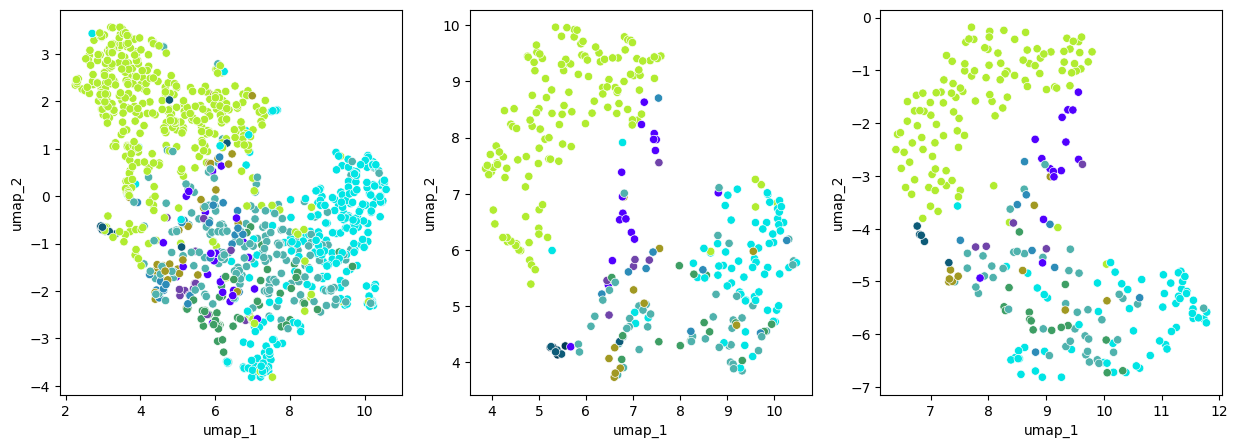

In [70]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,5))

sns.scatterplot(data=e_umap, x='umap_1', y='umap_2', hue='subclass_label_Hierarchical', palette=color_dict, ax=axes[0], legend=False)
sns.scatterplot(data=m_umap, x='umap_1', y='umap_2', hue='subclass_label_Hierarchical', palette=color_dict, ax=axes[1], legend=False)
sns.scatterplot(data=me_umap, x='umap_1', y='umap_2', hue='subclass_label_Hierarchical', palette=color_dict, ax=axes[2], legend=False)

In [72]:
#save
m_umap[['specimen_id', 'umap_1', 'umap_2']].to_csv(OUT_DIR / 'm_umap_aligned.csv', index=False)
e_umap[['specimen_id', 'umap_1', 'umap_2']].to_csv(OUT_DIR / 'e_umap_aligned.csv', index=False)
me_umap[['specimen_id', 'umap_1', 'umap_2']].to_csv(OUT_DIR / 'me_umap_aligned.csv', index=False)

In [73]:
OUT_DIR

PosixPath('/root/capsule/data/human/umaps/20260807')